# CIFAR-10 Image Classification with Advanced CNN

This notebook demonstrates the construction, training, and evaluation of a custom Convolutional Neural Network (CNN) built with PyTorch to classify images from the CIFAR-10 dataset. The model incorporates modern deep learning techniques such as **Data Augmentation**, **Batch Normalization**, **Dropout**, and learning rate scheduling to achieve robust performance.

---

## 1. Data Pipeline & Preprocessing

We use robust data augmentation techniques (`RandomHorizontalFlip`, `RandomCrop`, and `RandomRotation`) during training to prevent the model from memorizing the training data, thereby improving its ability to generalize to unseen images.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Data Augmentation and Normalization
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 128

trainset = torchvision.datasets.CIFAR10(root='./Data', train=True, download=True, transform=train_transform)
testset = torchvision.datasets.CIFAR10(root='./Data', train=False, download=True, transform=test_transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')




100%|██████████| 170M/170M [39:05<00:00, 72.7kB/s]


## 2. Modern CNN Architecture

The network is structured into three main convolutional blocks. **Batch Normalization** is used after convolution layers to accelerate training and provide a slight regularization effect. **Max Pooling** reduces spatial dimensions, and **Dropout** is applied to prevent overfitting by randomly disabling neurons during training.

In [2]:
class AdvancedCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Block 1: Input 32x32 -> Output 16x16
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Block 2: Input 16x16 -> Output 8x8
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)

        # Block 3: Input 8x8 -> Output 4x4
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(256)

        # Pooling & Regularization
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.2)
        self.fc_dropout = nn.Dropout(0.5)

        # Fully Connected Layers
        self.fc1 = nn.Linear(256 * 4 * 4, 512)
        self.fc2 = nn.Linear(512, 10)

    def forward(self, x):
        # Block 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)
        x = self.dropout(x)

        # Block 2
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)
        x = self.dropout(x)

        # Block 3
        x = F.relu(self.bn5(self.conv5(x)))
        x = self.pool(x)
        x = self.dropout(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully Connected
        x = F.relu(self.fc1(x))
        x = self.fc_dropout(x)
        x = self.fc2(x)

        return x

model = AdvancedCNN().to(device)


## 3. Training & Evaluation Pipeline

We use the **AdamW** optimizer with Weight Decay, which is highly effective for CNNs. A **Cosine Annealing Learning Rate** scheduler (`CosineAnnealingLR`) is employed to smoothly decrease the learning rate over the 15 epochs, helping the model settle into a more stable and optimal minimum.

In [3]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

epochs = 15
print(f"Training on {device}...")

# Lists to store metrics for visualization
train_losses = []
test_accuracies = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    scheduler.step()

    # Calculate average loss for the epoch
    epoch_loss = running_loss / len(trainloader)
    train_losses.append(epoch_loss)

    # Evaluation phase
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    test_accuracies.append(accuracy)

    print(f'Epoch {epoch + 1}/{epochs} | Loss: {epoch_loss:.3f} | Test Accuracy: {accuracy:.2f}%')

print('Finished Training')

Training on cuda...
Epoch 1/15 | Loss: 1.704 | Test Accuracy: 49.19%
Epoch 2/15 | Loss: 1.351 | Test Accuracy: 58.41%
Epoch 3/15 | Loss: 1.205 | Test Accuracy: 65.84%
Epoch 4/15 | Loss: 1.117 | Test Accuracy: 66.99%
Epoch 5/15 | Loss: 1.035 | Test Accuracy: 69.51%
Epoch 6/15 | Loss: 0.967 | Test Accuracy: 73.14%
Epoch 7/15 | Loss: 0.909 | Test Accuracy: 75.60%
Epoch 8/15 | Loss: 0.863 | Test Accuracy: 74.75%
Epoch 9/15 | Loss: 0.819 | Test Accuracy: 77.86%
Epoch 10/15 | Loss: 0.785 | Test Accuracy: 78.92%
Epoch 11/15 | Loss: 0.758 | Test Accuracy: 80.51%
Epoch 12/15 | Loss: 0.729 | Test Accuracy: 80.68%
Epoch 13/15 | Loss: 0.705 | Test Accuracy: 81.06%
Epoch 14/15 | Loss: 0.698 | Test Accuracy: 81.38%
Epoch 15/15 | Loss: 0.688 | Test Accuracy: 81.56%
Finished Training


## 4. Visualizing Training Metrics

Visualizing the **Training Loss** and **Test Accuracy** over epochs is crucial to evaluate the model's convergence pattern and diagnose whether the network is overfitting or underfitting.

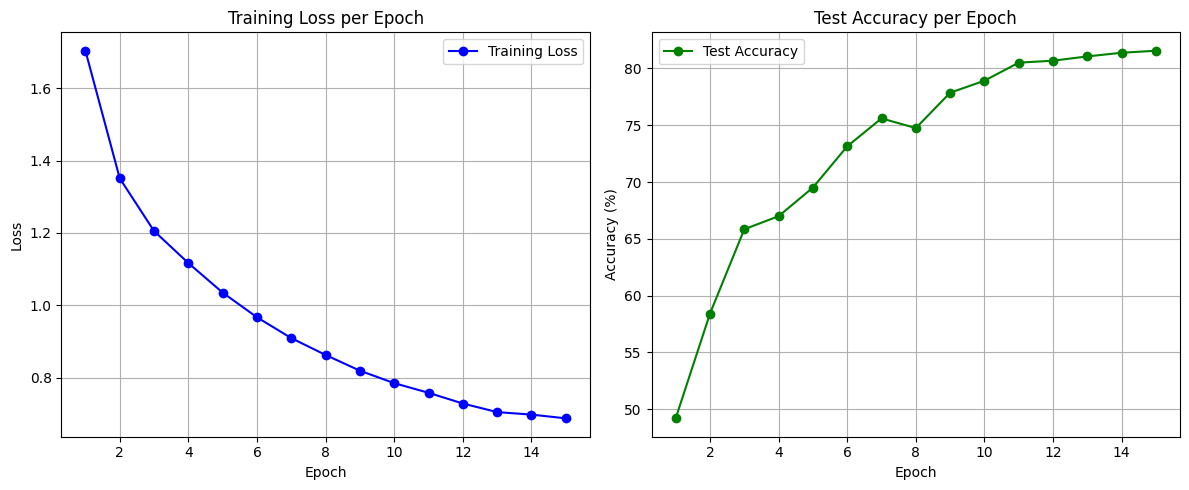

In [4]:
plt.figure(figsize=(12, 5))

# Plot Training Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, marker='o', color='b', label='Training Loss')
plt.title('Training Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# Plot Test Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), test_accuracies, marker='o', color='g', label='Test Accuracy')
plt.title('Test Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


## 5. Saving the Model

Finally, we save the trained model's parameters (**state dictionary**) to disk. This is a best practice in MLOps, allowing us to reload the exact weights later for deployment, inference, or further fine-tuning without restarting the training process.

In [7]:
model_path = 'cifar10_advanced_cnn.pth'
torch.save(model.state_dict(), model_path)
print(f"Model successfully saved to {model_path}")

# Example of how to load the model later:
# loaded_model = AdvancedCNN()
# loaded_model.load_state_dict(torch.load(model_path))
# loaded_model.to(device)
# loaded_model.eval()


Model successfully saved to cifar10_advanced_cnn.pth
